In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from osekit.utils.timestamp import strptime_from_text
from pandas import Timedelta, Timestamp, read_csv

from disclose.utils.filtering import read_dataframe
from disclose.utils.glider import (
    compute_acoustic_diversity,
    load_glider_nav,
    plot_detections_with_nav_data,
)

### Load data

In [3]:
input_dir = Path(r"_static/OHAGEODAMS_nav")
nav = load_glider_nav(input_dir)
nav = nav[nav["Timestamp"] > Timestamp("2024-02-21", tz="UTC")]
df = read_dataframe(Path(r"_static/OHAGEODAMS_results.csv"))

Reading navigation data: 100%|██████████| 56/56 [00:00<00:00, 272.59file/s]


### Plot detection with nav data

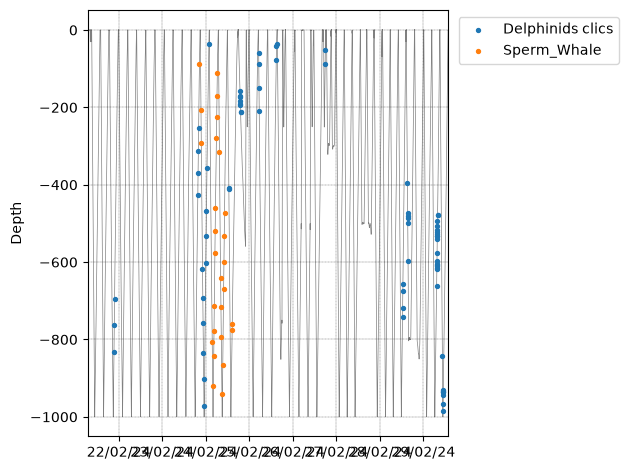

In [6]:
# plot specific labels
plot_detections_with_nav_data(
    df=df[df["label"].isin(["Sperm_Whale", "Delphinids clics"])],
    nav=nav,
    criterion="Depth",
    ticks=Timedelta("1D"),
)
plt.show()

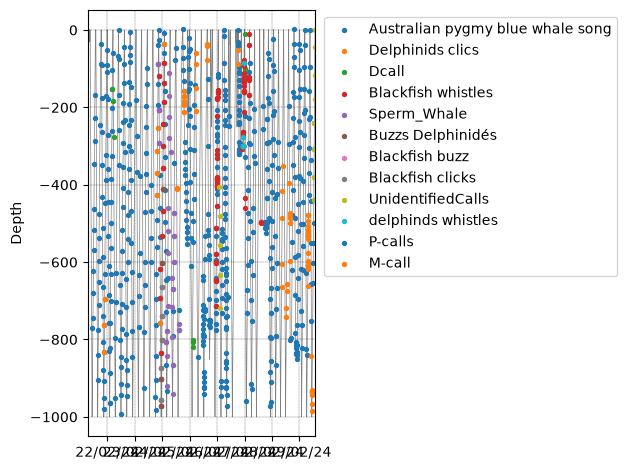

In [7]:
# plot all labels
plot_detections_with_nav_data(
    df=df,
    nav=nav,
    criterion="Depth",
    ticks=Timedelta("1D"),
)
plt.show()

### Compute acoustic diversity

In [8]:
task_status_filenames = read_csv(Path(r"_static/OHAGEODAMS_results.csv"))["filename"]
time_vector = [
    strptime_from_text(f, "%Y_%m_%d_%H_%M_%S").tz_localize("UTC")
    for f in task_status_filenames
]

df_acoustic_div = compute_acoustic_diversity(df=df, nav=nav, time_vector=time_vector)

Setting trajectory: 100%|██████████| 36252/36252 [00:10<00:00, 3347.62it/s]
